# TC2038 Situation Problem 1: algorithmic analysis of SARS-CoV-2 sequences

Santiago Hernández, A01787550

This notebook reads the six sequence files of the assignment and applies the
algorithm design techniques of the course to them. Every string algorithm is
written from scratch (no `str.find`, no library search or alignment). numpy is
used only to vectorize dynamic programming rows and for plotting.

Structure, following the parts of the assignment:

0. setup
1. understanding the data
2. sequence searching: naive, KMP, Z
3. flagship: dynamic programming (LCS) and divide and conquer (Hirschberg), Wuhan vs Texas
4. greedy: maximum set of non-overlapping ORFs
5. backtracking: locating each protein's coding region
6. branch and bound: most frequent k-mer with mismatches
7. extra: palindromes with Manacher
8. performance
9. summary

## 0. setup

Data is read from `./data/`. In Colab, upload the six files when prompted.
Figures and tables are written next to the LaTeX report when it exists,
otherwise into `./figures/` and `./tables/`.

In [1]:
import os
import shutil
import time
import math
import heapq
import itertools
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = "data"
FILES = {
    "wuhan": "SARS-COV-2-MN908947.3.txt",
    "texas": "SARS-COV-2-MT106054.1.txt",
    "orf1ab": "gen-ORF1AB.txt",
    "S": "gen-S.txt",
    "M": "gen-M.txt",
    "proteins": "seq-proteins.txt",
}

missing = [f for f in FILES.values() if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    try:
        from google.colab import files as colab_files
        os.makedirs(DATA_DIR, exist_ok=True)
        print("upload:", ", ".join(missing))
        for name, content in colab_files.upload().items():
            with open(os.path.join(DATA_DIR, name), "wb") as fh:
                fh.write(content)
    except ImportError:
        raise FileNotFoundError(f"missing data files in {DATA_DIR}: {missing}")

ESSAY_DIR = os.path.join("..", "essay")
FIG_DIR = os.path.join(ESSAY_DIR, "figures") if os.path.isdir(ESSAY_DIR) else "figures"
TAB_DIR = os.path.join(ESSAY_DIR, "tables") if os.path.isdir(ESSAY_DIR) else "tables"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)

PALETTE = ["#bc80bd", "#fb8072", "#b3de69", "#fdb462", "#80b1d3", "#8dd3c7", "#bebada", "#ffed6f"]


def latex_available():
    # figure text goes through latex when a working installation exists (so fonts
    # match the report); otherwise matplotlib's own mathtext is used
    if not (shutil.which("latex") and shutil.which("dvipng")):
        return False
    try:
        with plt.rc_context({"text.usetex": True}):
            fig = plt.figure(figsize=(1, 1))
            fig.text(0.5, 0.5, r"$x^2$")
            fig.canvas.draw()
            plt.close(fig)
        return True
    except Exception:
        return False


USETEX = latex_available()
AMP = r"\&" if USETEX else "&"
plt.rcParams.update({
    "text.usetex": USETEX,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}",
    "figure.figsize": (6.3, 3.9),
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "font.family": "serif",
    "mathtext.fontset": "stix",
    "axes.prop_cycle": plt.cycler("color", PALETTE),
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "axes.linewidth": 0.6,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "legend.framealpha": 0.8,
    "lines.linewidth": 1.2,
    "patch.force_edgecolor": True,
    "patch.linewidth": 0.6,
    "patch.edgecolor": "black",
})


def save_fig(fig, name):
    path = os.path.join(FIG_DIR, name + ".png")
    fig.savefig(path)
    print("saved", path)


def save_table(name, tex):
    path = os.path.join(TAB_DIR, name + ".tex")
    with open(path, "w") as fh:
        fh.write(tex)
    print("saved", path)


def bench(fn, *args, repeats=3):
    # min of repeats: the least noisy estimate of the true cost
    best = math.inf
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn(*args)
        best = min(best, time.perf_counter() - t0)
    return best


def loglog_slope(ns, ts):
    # exponent b in t ~ n^b, from a least squares fit in log space
    return float(np.polyfit(np.log(ns), np.log(ts), 1)[0])


BENCH = {}
print("latex for figure text:", USETEX)
print("figures ->", FIG_DIR)
print("tables  ->", TAB_DIR)

latex for figure text: True
figures -> ../essay/figures
tables  -> ../essay/tables


## 1. understanding the data

All files are FASTA: a header line starting with `>` followed by sequence
lines. The gene files carry their genome coordinates in the header
(`MN908947.3:21563-25384` for gene S), which later gives a free correctness
check for the search algorithms. `seq-proteins.txt` holds several records.

Reading policy: lines are stripped of whitespace and carriage returns and
uppercased. Any symbol outside the expected alphabet (ACGT for DNA, the 20
amino-acid letters for proteins) is counted and reported as unexpected. Such
symbols are kept in the sequence so positions stay faithful to the file, but
they are excluded from the frequency plots and can never match a pattern.

In [2]:
DNA_ALPHABET = "ACGT"
PROTEIN_ALPHABET = "ACDEFGHIKLMNPQRSTVWY"


def read_fasta(path):
    records, header, chunks = [], None, []
    with open(path, encoding="utf8") as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            if line[0] == ">":
                if header is not None:
                    records.append((header, "".join(chunks).upper()))
                header, chunks = line[1:], []
            else:
                chunks.append(line)
    if header is not None:
        records.append((header, "".join(chunks).upper()))
    return records


def header_coords(header):
    # "MN908947.3:21563-25384 Severe acute ..." -> (21563, 25384), 1-based inclusive
    token = header.split()[0]
    if ":" not in token:
        return None
    lo, hi = token.split(":")[1].split("-")
    return int(lo), int(hi)


def characterize(name, seq, expected):
    counts = Counter(seq)
    valid = {s: counts[s] for s in expected if counts[s]}
    unexpected = {s: c for s, c in counts.items() if s not in expected}
    total_valid = sum(valid.values())
    freq = {s: c / total_valid for s, c in valid.items()}
    ranked = sorted(valid.items(), key=lambda kv: kv[1])
    return {
        "name": name,
        "length": len(seq),
        "alphabet": "".join(sorted(counts)),
        "counts": valid,
        "freq": freq,
        "most": ranked[-1][0],
        "least": ranked[0][0],
        "unexpected": unexpected,
    }


SEQ = {}
for key, fname in FILES.items():
    recs = read_fasta(os.path.join(DATA_DIR, fname))
    if key == "proteins":
        PROTEINS = recs
        SEQ[key] = "".join(s for _, s in recs)
    else:
        assert len(recs) == 1, f"{fname} should hold one record"
        SEQ[key] = recs[0][1]
        SEQ[key + "_header"] = recs[0][0]

GENE_COORDS = {g: header_coords(SEQ[g + "_header"]) for g in ("orf1ab", "S", "M")}
print("gene coordinates from headers (1-based):", GENE_COORDS)
print("protein records:", len(PROTEINS))

gene coordinates from headers (1-based): {'orf1ab': (266, 21555), 'S': (21563, 25384), 'M': (26523, 27191)}
protein records: 24


In [3]:
STATS = {}
for key in ("wuhan", "texas", "orf1ab", "S", "M"):
    STATS[key] = characterize(FILES[key], SEQ[key], DNA_ALPHABET)
STATS["proteins"] = characterize(FILES["proteins"], SEQ["proteins"], PROTEIN_ALPHABET)

print(f"{'file':28s} {'length':>7s}  {'alphabet':22s} {'most':>4s} {'least':>5s}  unexpected")
for st in STATS.values():
    print(f"{st['name']:28s} {st['length']:7d}  {st['alphabet']:22s} {st['most']:>4s} {st['least']:>5s}  {st['unexpected'] or 'none'}")

print("\nsymbol counts and relative frequencies")
for st in STATS.values():
    if st["name"] == FILES["proteins"]:
        continue
    row = "  ".join(f"{s}={st['counts'][s]} ({st['freq'][s]:.3f})" for s in DNA_ALPHABET)
    print(f"{st['name']:28s} {row}")

print("\nprotein records (id, length):")
print(", ".join(f"{h}:{len(s)}" for h, s in PROTEINS))

file                          length  alphabet               most least  unexpected
SARS-COV-2-MN908947.3.txt      29903  ACGT                      T     C  none
SARS-COV-2-MT106054.1.txt      29882  ACGT                      T     C  none
gen-ORF1AB.txt                 21290  ACGT                      T     C  none
gen-S.txt                       3822  ACGT                      T     G  none
gen-M.txt                        669  ACGT                      T     G  none
seq-proteins.txt                9701  ACDEFGHIKLMNPQRSTVWY      L     W  none

symbol counts and relative frequencies
SARS-COV-2-MN908947.3.txt    A=8954 (0.299)  C=5492 (0.184)  G=5863 (0.196)  T=9594 (0.321)
SARS-COV-2-MT106054.1.txt    A=8933 (0.299)  C=5492 (0.184)  G=5863 (0.196)  T=9594 (0.321)
gen-ORF1AB.txt               A=6425 (0.302)  C=3744 (0.176)  G=4230 (0.199)  T=6891 (0.324)
gen-S.txt                    A=1125 (0.294)  C=723 (0.189)  G=703 (0.184)  T=1271 (0.333)
gen-M.txt                    A=171 (0.256)

saved ../essay/figures/fig_freq_dna.png


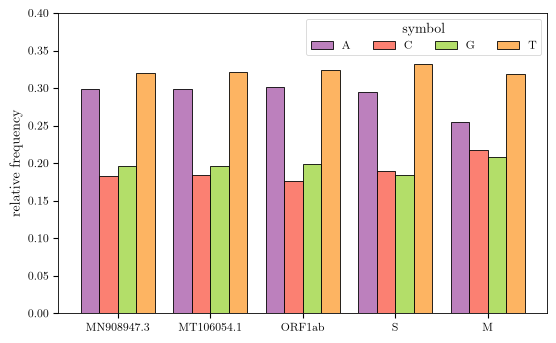

saved ../essay/figures/fig_freq_protein.png


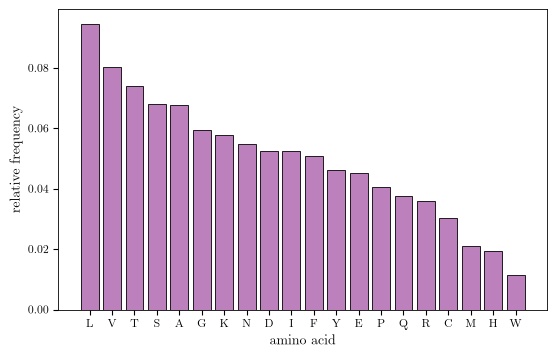

In [4]:
# figure: relative nucleotide frequencies per DNA file
dna_keys = ["wuhan", "texas", "orf1ab", "S", "M"]
labels = ["MN908947.3", "MT106054.1", "ORF1ab", "S", "M"]
x = np.arange(len(dna_keys))
w = 0.2
fig, ax = plt.subplots()
for i, s in enumerate(DNA_ALPHABET):
    ax.bar(x + (i - 1.5) * w, [STATS[k]["freq"][s] for k in dna_keys], w, label=s)
ax.set_xticks(x, labels)
ax.set_ylabel("relative frequency")
ax.set_ylim(0, 0.4)
ax.legend(title="symbol", ncol=4)
save_fig(fig, "fig_freq_dna")
plt.show()

# figure: pooled amino-acid frequencies
st = STATS["proteins"]
aa = sorted(st["freq"], key=lambda s: -st["freq"][s])
fig, ax = plt.subplots()
ax.bar(aa, [st["freq"][s] for s in aa], color=PALETTE[0])
ax.set_xlabel("amino acid")
ax.set_ylabel("relative frequency")
save_fig(fig, "fig_freq_protein")
plt.show()

In [5]:
# table for the report
rows = []
for st in STATS.values():
    unexpected = ", ".join(f"{s}:{c}" for s, c in st["unexpected"].items()) or "none"
    rows.append(f"{st['name'].replace('_', chr(92) + '_')} & {st['length']} & {len(st['counts'])} & {st['most']} & {st['least']} & {unexpected} \\\\")
tex = "\n".join([
    r"\begin{tabular}{lrrccl}",
    r"\hline",
    r"file & length & symbols & most & least & unexpected \\",
    r"\hline",
    *rows,
    r"\hline",
    r"\end{tabular}",
])
save_table("tab_datasets", tex)

saved ../essay/tables/tab_datasets.tex


## 2. sequence searching

Three exact pattern matchers, all returning the 0-based start positions of
every occurrence of `pattern` in `text`:

* naive: try every alignment and compare character by character. Worst case
  $O(nm)$ comparisons (text of length $n$, pattern of length $m$).
* KMP: preprocess the pattern into its failure table `lps` (longest proper
  prefix that is also a suffix) so that after a mismatch the text pointer never
  moves backwards. $O(n + m)$.
* Z: build the Z-array of `pattern + '#' + text`; every index whose Z-value
  equals $m$ is a match. $O(n + m)$.

The three are checked against each other on every search, and against the
genome coordinates stored in the gene headers.

In [6]:
def naive_search(text, pattern):
    n, m = len(text), len(pattern)
    positions = []
    for i in range(n - m + 1):
        j = 0
        while j < m and text[i + j] == pattern[j]:
            j += 1
        if j == m:
            positions.append(i)
    return positions


def build_lps(pattern):
    m = len(pattern)
    lps = [0] * m
    k = 0
    for i in range(1, m):
        while k > 0 and pattern[i] != pattern[k]:
            k = lps[k - 1]
        if pattern[i] == pattern[k]:
            k += 1
        lps[i] = k
    return lps


def kmp_search(text, pattern):
    n, m = len(text), len(pattern)
    if m == 0 or m > n:
        return []
    lps = build_lps(pattern)
    positions = []
    j = 0
    for i in range(n):
        while j > 0 and text[i] != pattern[j]:
            j = lps[j - 1]
        if text[i] == pattern[j]:
            j += 1
        if j == m:
            positions.append(i - m + 1)
            j = lps[j - 1]
    return positions


def z_function(s):
    n = len(s)
    z = [0] * n
    l = r = 0
    for i in range(1, n):
        if i < r:
            z[i] = min(r - i, z[i - l])
        while i + z[i] < n and s[z[i]] == s[i + z[i]]:
            z[i] += 1
        if i + z[i] > r:
            l, r = i, i + z[i]
    return z


def z_search(text, pattern, sep="#"):
    m = len(pattern)
    if m == 0 or m > len(text):
        return []
    z = z_function(pattern + sep + text)
    return [i - m - 1 for i in range(m + 1, len(z)) if z[i] == m]


def search_all(text, pattern):
    a, b, c = naive_search(text, pattern), kmp_search(text, pattern), z_search(text, pattern)
    assert a == b == c, "search algorithms disagree"
    return a


def report_search(text, pattern, label=""):
    pos = search_all(text, pattern)
    print(f"{label}pattern {pattern if len(pattern) <= 20 else pattern[:17] + '...'} (m={len(pattern)}) in text of n={len(text)}")
    print("  Pattern found:", "YES" if pos else "NO")
    print("  Number of occurrences:", len(pos))
    print("  Positions:", pos if len(pos) <= 12 else pos[:12] + ["..."])
    return pos


# the example from the assignment (its sequence is shown truncated in the brief,
# so the positions there refer to a longer text; these are the ones for the 17 symbols given)
_ = report_search("ACGTACGTTACGTACGT", "TACGT", "example: ")

example: pattern TACGT (m=5) in text of n=17
  Pattern found: YES
  Number of occurrences: 3
  Positions: [3, 8, 12]


In [7]:
# locate the three genes inside the wuhan genome and check the header coordinates
genome = SEQ["wuhan"]
GENE_POS = {}
for g in ("orf1ab", "S", "M"):
    pos = report_search(genome, SEQ[g], f"gene {g}: ")
    lo, hi = GENE_COORDS[g]
    assert pos == [lo - 1], f"gene {g}: found {pos}, header says {lo - 1}"
    assert hi - lo + 1 == len(SEQ[g])
    GENE_POS[g] = (pos[0], pos[0] + len(SEQ[g]))
print("\n0-based half-open gene spans:", GENE_POS)

# the same genes in the texas genome: a gene that has mutated will not be found
print()
for g in ("orf1ab", "S", "M"):
    _ = report_search(SEQ["texas"], SEQ[g], f"gene {g} in texas: ")

gene orf1ab: pattern ATGGAGAGCCTTGTCCC... (m=21290) in text of n=29903
  Pattern found: YES
  Number of occurrences: 1
  Positions: [265]
gene S: pattern ATGTTTGTTTTTCTTGT... (m=3822) in text of n=29903
  Pattern found: YES
  Number of occurrences: 1
  Positions: [21562]
gene M: pattern ATGGCAGATTCCAACGG... (m=669) in text of n=29903
  Pattern found: YES
  Number of occurrences: 1
  Positions: [26522]

0-based half-open gene spans: {'orf1ab': (265, 21555), 'S': (21562, 25384), 'M': (26522, 27191)}

gene orf1ab in texas: pattern ATGGAGAGCCTTGTCCC... (m=21290) in text of n=29882
  Pattern found: NO
  Number of occurrences: 0
  Positions: []
gene S in texas: pattern ATGTTTGTTTTTCTTGT... (m=3822) in text of n=29882
  Pattern found: YES
  Number of occurrences: 1
  Positions: [21562]
gene M in texas: pattern ATGGCAGATTCCAACGG... (m=669) in text of n=29882
  Pattern found: YES
  Number of occurrences: 1
  Positions: [26522]


In [8]:
# a short motif taken from the data itself: the most frequent 6-mer, by a single
# pass with a dictionary (this exact-count baseline is reused in section 6)
def kmer_counts(text, k):
    counts = defaultdict(int)
    for i in range(len(text) - k + 1):
        counts[text[i:i + k]] += 1
    return counts


counts6 = kmer_counts(genome, 6)
motif = max(counts6, key=counts6.get)
motif_pos = report_search(genome, motif, "most frequent 6-mer: ")
assert len(motif_pos) == counts6[motif]

most frequent 6-mer: pattern TTGTTA (m=6) in text of n=29903
  Pattern found: YES
  Number of occurrences: 42
  Positions: [1271, 1358, 2207, 3434, 4021, 4073, 4598, 5302, 5675, 6217, 6710, 7541, '...']


saved ../essay/figures/fig_gene_map.png


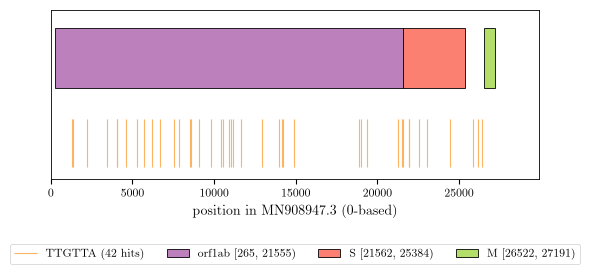

In [9]:
# figure: where the genes and the motif occurrences sit on the genome
fig, ax = plt.subplots(figsize=(6.3, 2.2))
n = len(genome)
for i, g in enumerate(("orf1ab", "S", "M")):
    a, b = GENE_POS[g]
    ax.barh(1, b - a, left=a, height=0.5, color=PALETTE[i], label=f"{g} [{a}, {b})")
ax.vlines(motif_pos, 0.1, 0.5, color=PALETTE[3], linewidth=0.8, label=f"{motif} ({len(motif_pos)} hits)")
ax.set_xlim(0, n)
ax.set_ylim(0, 1.4)
ax.set_yticks([])
ax.set_xlabel("position in MN908947.3 (0-based)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=4)
save_fig(fig, "fig_gene_map")
plt.show()

In [10]:
# benchmark: real text (genome prefixes, the first 30 nt of gene M as pattern) and an adversarial
# text (all A, pattern A...AC) where naive search does m comparisons at every
# alignment. results are collected in BENCH and plotted in section 8.
SIZES = [1000, 2000, 5000, 10000, 20000, len(genome)]
pat = SEQ["M"][:30]
BENCH["search_real"] = {"n": SIZES, "naive": [], "kmp": [], "z": []}
for n in SIZES:
    t = genome[:n]
    BENCH["search_real"]["naive"].append(bench(naive_search, t, pat, repeats=7))
    BENCH["search_real"]["kmp"].append(bench(kmp_search, t, pat, repeats=7))
    BENCH["search_real"]["z"].append(bench(z_search, t, pat, repeats=7))

m_adv = 50
pat_adv = "A" * (m_adv - 1) + "C"
BENCH["search_adv"] = {"n": SIZES, "naive": [], "kmp": [], "z": []}
for n in SIZES:
    t = "A" * n
    BENCH["search_adv"]["naive"].append(bench(naive_search, t, pat_adv, repeats=5))
    BENCH["search_adv"]["kmp"].append(bench(kmp_search, t, pat_adv, repeats=5))
    BENCH["search_adv"]["z"].append(bench(z_search, t, pat_adv, repeats=5))

for key in ("search_real", "search_adv"):
    b = BENCH[key]
    print(key, f"(pattern m={len(pat) if key == 'search_real' else m_adv})")
    print(f"  {'n':>6s} {'naive':>9s} {'kmp':>9s} {'z':>9s}")
    for i, n in enumerate(b["n"]):
        print(f"  {n:6d} {b['naive'][i]*1e3:8.2f}ms {b['kmp'][i]*1e3:8.2f}ms {b['z'][i]*1e3:8.2f}ms")
    print("  log-log slopes:", {k: round(loglog_slope(b["n"], b[k]), 2) for k in ("naive", "kmp", "z")})

search_real (pattern m=30)
       n     naive       kmp         z
    1000     0.05ms     0.05ms     0.11ms
    2000     0.10ms     0.09ms     0.23ms
    5000     0.27ms     0.24ms     0.59ms
   10000     0.53ms     0.47ms     1.16ms
   20000     1.06ms     0.93ms     2.35ms
   29903     1.58ms     1.44ms     3.62ms
  log-log slopes: {'naive': 1.03, 'kmp': 1.0, 'z': 1.02}
search_adv (pattern m=50)
       n     naive       kmp         z
    1000     1.31ms     0.07ms     0.17ms
    2000     2.49ms     0.13ms     0.34ms
    5000     6.39ms     0.32ms     0.85ms
   10000    13.39ms     0.68ms     1.73ms
   20000    26.45ms     1.24ms     3.44ms
   29903    41.47ms     1.96ms     4.80ms
  log-log slopes: {'naive': 1.02, 'kmp': 0.97, 'z': 0.99}


## 3. flagship: dynamic programming and divide and conquer

**Problem.** Compare the Wuhan 2019 genome (MN908947.3) with the Texas 2020
genome (MT106054.1): where are they the same, where do they differ, and do
the differences change amino acids?

**Technique 1, dynamic programming.** The longest common subsequence (LCS)
is defined by the recurrence

$$LCS(i, j) = \begin{cases} 0 & i = 0 \text{ or } j = 0 \\ 1 + LCS(i-1, j-1) & X_i = Y_j \\ \max(LCS(i-1, j), LCS(i, j-1)) & X_i \ne Y_j \end{cases}$$

Filling the $(n+1)(m+1)$ table costs $O(nm)$ time and $O(nm)$ space. For the
two genomes that table has $29903 \times 29882 \approx 8.9 \times 10^8$ cells,
about 3.6 GB at 4 bytes per cell, which does not fit in a Colab session.

**Technique 2, divide and conquer.** Hirschberg's algorithm computes the same
LCS in $O(n + m)$ space. Only the last row of the DP table is needed to know
the LCS *length*, and it can be computed with two rows. To recover the
subsequence itself: split $X$ at its midpoint, compute the last DP row of
$X[:mid]$ against $Y$ (forward) and of $X[mid:]$ against $Y$ (both reversed),
choose the split $k$ of $Y$ that maximizes the sum of the two rows, then solve
the two halves recursively and concatenate. The recursion tree has depth
$O(\log n)$, the work halves at each level, and the total is still $O(nm)$
time but never more than a few rows of memory.

Three LCS implementations are checked against each other:

* `lcs_table`: pure Python full table with traceback (the oracle),
* `lcs_rows_py`: pure Python two-row version, length only,
* `lcs_last_row`: numpy row version used inside Hirschberg. A DP row is a
  running maximum: when $X_i = Y_j$ the diagonal value plus one dominates
  both neighbours, otherwise the cell is the max of its two neighbours, so
  `row[j] = max(cand[j], row[j-1])` with `cand[j]` the diagonal-or-above
  candidate, which numpy computes with `maximum.accumulate`.

In [11]:
def lcs_table(X, Y):
    # full table with traceback: returns the table and the matched index pairs
    n, m = len(X), len(Y)
    T = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(1, n + 1):
        xi, prev, cur = X[i - 1], T[i - 1], T[i]
        for j in range(1, m + 1):
            if xi == Y[j - 1]:
                cur[j] = prev[j - 1] + 1
            else:
                cur[j] = prev[j] if prev[j] >= cur[j - 1] else cur[j - 1]
    pairs = []
    i, j = n, m
    while i > 0 and j > 0:
        if X[i - 1] == Y[j - 1]:
            pairs.append((i - 1, j - 1))
            i, j = i - 1, j - 1
        elif T[i - 1][j] >= T[i][j - 1]:
            i -= 1
        else:
            j -= 1
    pairs.reverse()
    return T, pairs


def lcs_rows_py(X, Y):
    # two rows only: the length in o(m) space
    m = len(Y)
    prev = [0] * (m + 1)
    for xi in X:
        cur = [0] * (m + 1)
        for j in range(1, m + 1):
            if xi == Y[j - 1]:
                cur[j] = prev[j - 1] + 1
            else:
                cur[j] = prev[j] if prev[j] >= cur[j - 1] else cur[j - 1]
        prev = cur
    return prev[m]


def to_arr(s):
    return np.frombuffer(s.encode("ascii"), dtype=np.uint8)


def lcs_last_row(Xa, Ya):
    # numpy row dp: returns the last dp row (length m+1) as int32
    m = len(Ya)
    prev = np.zeros(m + 1, dtype=np.int32)
    cur = np.zeros(m + 1, dtype=np.int32)
    for x in Xa:
        cand = np.where(Ya == x, prev[:-1] + 1, prev[1:])
        np.maximum.accumulate(cand, out=cur[1:])
        prev, cur = cur, prev
    return prev


def lcs_pairs_small(Xa, Ya):
    # full numpy table with traceback, used for the base case of hirschberg
    n, m = len(Xa), len(Ya)
    T = np.zeros((n + 1, m + 1), dtype=np.int32)
    for i in range(1, n + 1):
        cand = np.where(Ya == Xa[i - 1], T[i - 1, :-1] + 1, T[i - 1, 1:])
        np.maximum.accumulate(cand, out=T[i, 1:])
    pairs = []
    i, j = n, m
    while i > 0 and j > 0:
        if Xa[i - 1] == Ya[j - 1]:
            pairs.append((i - 1, j - 1))
            i, j = i - 1, j - 1
        elif T[i - 1, j] >= T[i, j - 1]:
            i -= 1
        else:
            j -= 1
    pairs.reverse()
    return pairs


def hirschberg(Xa, Ya, xoff=0, yoff=0, splits=None, depth=0, base_cells=40_000):
    # divide and conquer lcs: o(n + m) memory, returns matched index pairs
    n, m = len(Xa), len(Ya)
    if n == 0 or m == 0:
        return []
    if n == 1:
        # a single symbol: its first occurrence in y, if any (keeps mid >= 1 below)
        for j in range(m):
            if Ya[j] == Xa[0]:
                return [(xoff, yoff + j)]
        return []
    if n * m <= base_cells:
        return [(i + xoff, j + yoff) for i, j in lcs_pairs_small(Xa, Ya)]
    mid = n // 2
    fwd = lcs_last_row(Xa[:mid], Ya)
    bwd = lcs_last_row(Xa[mid:][::-1], Ya[::-1])
    k = int(np.argmax(fwd + bwd[::-1]))
    if splits is not None:
        splits.append((depth, xoff + mid, yoff + k))
    left = hirschberg(Xa[:mid], Ya[:k], xoff, yoff, splits, depth + 1, base_cells)
    right = hirschberg(Xa[mid:], Ya[k:], xoff + mid, yoff + k, splits, depth + 1, base_cells)
    return left + right


def is_common_subsequence(X, Y, pairs):
    pi = pj = -1
    for i, j in pairs:
        if not (i > pi and j > pj and X[i] == Y[j]):
            return False
        pi, pj = i, j
    return True


def lcs_bitparallel(X, Y):
    # independent oracle for the length only (hyyro's bit-parallel recurrence on python
    # big ints): a different algorithm, used to cross-check the row trick and hirschberg
    m = len(Y)
    full = (1 << m) - 1
    masks = {}
    for j, c in enumerate(Y):
        masks[c] = masks.get(c, 0) | (1 << j)
    v = full
    for c in X:
        mk = masks.get(c, 0)
        v = ((v + (v & mk)) | (v & ~mk)) & full
    return m - bin(v).count("1")


def check_lcs(X, Y, base_cells=40_000):
    T, pairs_t = lcs_table(X, Y)
    Xa, Ya = to_arr(X), to_arr(Y)
    pairs_h = hirschberg(Xa, Ya, base_cells=base_cells)
    lengths = {T[len(X)][len(Y)], lcs_rows_py(X, Y), int(lcs_last_row(Xa, Ya)[-1]), lcs_bitparallel(X, Y), len(pairs_t), len(pairs_h)}
    assert len(lengths) == 1, (X[:20], Y[:20], lengths)
    assert is_common_subsequence(X, Y, pairs_t) and is_common_subsequence(X, Y, pairs_h)
    return lengths.pop()


# textbook case (clrs figure 15.8) and degenerate cases
assert check_lcs("ABCBDAB", "BDCABA") == 4
assert check_lcs("AAAA", "TTTT") == 0 and check_lcs("", "ACGT") == 0 and check_lcs("ACGT", "ACGT") == 4

# random strings of different lengths, with the recursion forced down to tiny base cases
rng = np.random.default_rng(1)
for _ in range(200):
    n, m = int(rng.integers(0, 60)), int(rng.integers(0, 60))
    X = "".join(rng.choice(list("ACGT"), n))
    Y = "".join(rng.choice(list("ACGT"), m))
    check_lcs(X, Y, base_cells=int(rng.choice([1, 8, 40])))
print("200 random cases: all implementations agree, pairs valid")

# real windows that contain substitutions, shifts, and unequal lengths
for (xa, xb, ya, yb) in [(8000, 9500, 8000, 9500), (18000, 19500, 18100, 19400), (28800, 29903, 28700, 29882), (0, 1200, 300, 1000)]:
    l = check_lcs(SEQ["wuhan"][xa:xb], SEQ["texas"][ya:yb], base_cells=2000)
    print(f"wuhan[{xa}:{xb}] vs texas[{ya}:{yb}]: lcs {l}, all implementations agree")

200 random cases: all implementations agree, pairs valid


wuhan[8000:9500] vs texas[8000:9500]: lcs 1499, all implementations agree


wuhan[18000:19500] vs texas[18100:19400]: lcs 1297, all implementations agree
wuhan[28800:29903] vs texas[28700:29882]: lcs 1081, all implementations agree


wuhan[0:1200] vs texas[300:1000]: lcs 700, all implementations agree


In [12]:
# the full genomes: hirschberg only, the table would need ~3.6 GB
X, Y = SEQ["wuhan"], SEQ["texas"]
Xa, Ya = to_arr(X), to_arr(Y)
SPLITS = []
t0 = time.perf_counter()
PAIRS = hirschberg(Xa, Ya, splits=SPLITS)
t_hirschberg = time.perf_counter() - t0
t0 = time.perf_counter()
lcs_len_np = int(lcs_last_row(Xa, Ya)[-1])
t_rows = time.perf_counter() - t0
assert lcs_len_np == len(PAIRS) == lcs_bitparallel(X, Y) and is_common_subsequence(X, Y, PAIRS)

LCS_LEN = len(PAIRS)
SIMILARITY = LCS_LEN / max(len(X), len(Y))
print(f"|X| = {len(X)} (wuhan), |Y| = {len(Y)} (texas)")
print(f"|LCS| = {LCS_LEN}")
print(f"similarity |LCS| / max(|X|, |Y|) = {SIMILARITY:.5f}")
print(f"hirschberg (with alignment): {t_hirschberg:.2f} s, numpy rows (length only): {t_rows:.2f} s")
print(f"full table would need {len(X) * len(Y) * 4 / 1e9:.2f} GB; hirschberg peak is a few rows of {len(Y) + 1} int32")
print(f"recursion: {len(SPLITS)} split points, max depth {max(d for d, _, _ in SPLITS)}")

|X| = 29903 (wuhan), |Y| = 29882 (texas)
|LCS| = 29875
similarity |LCS| / max(|X|, |Y|) = 0.99906
hirschberg (with alignment): 3.69 s, numpy rows (length only): 1.64 s
full table would need 3.57 GB; hirschberg peak is a few rows of 29883 int32
recursion: 255 split points, max depth 7


### from the LCS to a list of differences

Consecutive matched pairs $(i, j)$ and $(i', j')$ delimit an unmatched gap
$X[i+1:i']$ against $Y[j+1:j']$. Because the LCS is optimal the two sides of
a gap share no symbol at all (a shared symbol could be matched and the LCS
would grow), so a gap with equal lengths on both sides is a run of
substitutions, a gap with one empty side is an insertion or a deletion, and
anything else is a complex change.

For every substitution inside a coding region we translate the affected
codon in both genomes with the standard genetic code and classify it as
synonymous (same amino acid) or non-synonymous. Reading frames: genes S and M
start at their header coordinate. ORF1ab is translated in two frames because
of the ribosomal frameshift at position 13468 (1-based): the ORF1a frame from
266 and the ORF1b frame from 13468. Both frames and the codon table itself are
validated against `seq-proteins.txt` before they are used.

In [13]:
BASES = "TCAG"
AMINO = "FFLLSSSSYY**CC*WLLLLPPPPHHQQRRRRIIIMTTTTNNKKSSRRVVVVAAAADDEEGGGG"
CODON = {a + b + c: AMINO[16 * i + 4 * j + k]
         for i, a in enumerate(BASES) for j, b in enumerate(BASES) for k, c in enumerate(BASES)}
CODONS_FOR = defaultdict(list)
for cod, aa in CODON.items():
    CODONS_FOR[aa].append(cod)


def translate(dna):
    return "".join(CODON.get(dna[i:i + 3], "X") for i in range(0, len(dna) - 2, 3))


# validate the codon table and the gene frames against the protein file
PROT = dict(PROTEINS)
prot_S = translate(SEQ["S"])
prot_M = translate(SEQ["M"])
assert prot_S.rstrip("*") == PROT["QHD43416"], "gene S does not translate to the spike record"
assert prot_M.rstrip("*") == PROT["QHD43419"], "gene M does not translate to the M record"
print("codon table check: gene S -> QHD43416 (spike), gene M -> QHD43419, both exact")

FS = 13468 - 1  # 0-based position of the frameshift
orf1a_tr = translate(genome[265:FS])
orf1b_tr = translate(genome[FS:GENE_POS["orf1ab"][1]])


def proteins_in(translation):
    return [pid for pid, p in PROTEINS if kmp_search(translation, p)]


found_a, found_b = proteins_in(orf1a_tr), proteins_in(orf1b_tr)
print("protein records found whole in the ORF1a frame:", found_a)
print("protein records found whole in the ORF1b frame:", found_b)
assert len(found_a) >= 5 and len(found_b) >= 3, "frames not validated"

# coding regions used for the classification: (name, start, end, frame_start), 0-based half-open
CODING = [
    ("ORF1a", 265, FS, 265),
    ("ORF1b", FS, GENE_POS["orf1ab"][1], FS),
    ("S", *GENE_POS["S"], GENE_POS["S"][0]),
    ("M", *GENE_POS["M"], GENE_POS["M"][0]),
]

codon table check: gene S -> QHD43416 (spike), gene M -> QHD43419, both exact
protein records found whole in the ORF1a frame: ['QHD43415_1', 'QHD43415_2', 'QHD43415_3', 'QHD43415_4', 'QHD43415_5', 'QHD43415_6', 'QHD43415_7', 'QHD43415_8', 'QHD43415_9', 'QHD43415_10']
protein records found whole in the ORF1b frame: ['QHD43415_12', 'QHD43415_13', 'QHD43415_14', 'QHD43415_15']


In [14]:
def alignment_events(X, Y, pairs):
    events = []
    pi = pj = -1
    for i, j in list(pairs) + [(len(X), len(Y))]:
        gx, gy = i - pi - 1, j - pj - 1
        if gx or gy:
            kind = "substitution" if gx == gy else "insertion" if gx == 0 else "deletion" if gy == 0 else "complex"
            events.append({"kind": kind, "x": pi + 1, "xlen": gx, "y": pj + 1, "ylen": gy,
                           "xseq": X[pi + 1:i], "yseq": Y[pj + 1:j]})
        pi, pj = i, j
    return events


def classify_substitution(X, Y, x, y, coding):
    # returns (region, codon_x, codon_y, aa_x, aa_y) or region 'non-coding'
    for name, start, end, frame in coding:
        if start <= x < end:
            c0 = frame + 3 * ((x - frame) // 3)
            cx = X[c0:c0 + 3]
            # rebuild the texas codon around the aligned position
            cy = cx[:x - c0] + Y[y] + cx[x - c0 + 1:]
            return name, cx, cy, CODON.get(cx, "?"), CODON.get(cy, "?")
    return "non-coding", "", "", "", ""


def classify_substitutions(events, coding, outside="outside"):
    subs = []
    for e in events:
        if e["kind"] != "substitution":
            continue
        for k in range(e["xlen"]):
            x, y = e["x"] + k, e["y"] + k
            region, cx, cy, ax_, ay_ = classify_substitution(X, Y, x, y, coding)
            if region == "non-coding":
                region, effect = outside, ""
            else:
                effect = "synonymous" if ax_ == ay_ else "non-synonymous"
            subs.append({"x": x, "y": y, "from": X[x], "to": Y[y], "region": region,
                         "codon": f"{cx}>{cy}" if cx else "", "aa": f"{ax_}>{ay_}" if cx else "", "effect": effect})
    return subs


def print_substitutions(subs):
    print(f"{'wuhan':>6s} {'texas':>6s} {'change':>7s} {'region':>12s} {'codon':>9s} {'aa':>5s}  effect")
    for s in subs:
        print(f"{s['x']:6d} {s['y']:6d} {s['from'] + '>' + s['to']:>7s} {s['region']:>12s} {s['codon']:>9s} {s['aa']:>5s}  {s['effect']}")


EVENTS = alignment_events(X, Y, PAIRS)
SUBS = classify_substitutions(EVENTS, CODING, outside="outside 3 genes")
kinds = Counter(e["kind"] for e in EVENTS)
effects = Counter(s["effect"] or "outside" for s in SUBS)
print("alignment events:", dict(kinds))
print("substituted positions:", len(SUBS), dict(effects))
print_substitutions(SUBS)
print("\nindels and complex gaps:")
for e in EVENTS:
    if e["kind"] != "substitution":
        print(f"  {e['kind']:9s} wuhan[{e['x']}:{e['x'] + e['xlen']}]={e['xseq'] or '-'}  texas[{e['y']}:{e['y'] + e['ylen']}]={e['yseq'] or '-'}")

alignment events: {'substitution': 6, 'insertion': 1, 'deletion': 2}
substituted positions: 6 {'synonymous': 3, 'non-synonymous': 1, 'outside': 2}
 wuhan  texas  change       region     codon    aa  effect
  8781   8781     C>T        ORF1a   AGC>AGT   S>S  synonymous
 18602  18602     T>C        ORF1b   CAT>CAC   H>H  synonymous
 18974  18974     T>A        ORF1b   GTT>GTA   V>V  synonymous
 19174  19174     A>C        ORF1b   GAT>GCT   D>A  non-synonymous
 27924  27924     C>T outside 3 genes                  
 28143  28143     T>C outside 3 genes                  

indels and complex gaps:
  insertion wuhan[29091:29091]=-  texas[29091:29092]=T
  deletion  wuhan[29094:29095]=C  texas[29095:29095]=-
  deletion  wuhan[29870:29891]=AAAAAAAAAAAAAAAAAAAAA  texas[29870:29870]=-


A limitation to keep in mind when reading the indels: the LCS has no
substitution operation. When a substituted base is equal to one of its
neighbours, an insertion and a deletion a few positions apart give exactly the
same LCS length as a substitution, and the traceback may return either. The
pair at 29091/29094 is such a case: Wuhan `GCTTTCGG` against Texas `GCTTTTGG`
is a single C>T at position 29094 (29095 1-based), reported as insert-T plus
delete-C. The run of A missing from the Texas record is the poly-A tail, a
difference in how far the sequencing read, not a mutation.

In [15]:
# tables for the report
def save_comparison_tables(subs, suffix=""):
    effects = Counter(s["effect"] or "outside" for s in subs)
    rows = [
        f"MN908947.3 (Wuhan) length & {len(X)} \\\\",
        f"MT106054.1 (Texas) length & {len(Y)} \\\\",
        f"$|LCS|$ & {LCS_LEN} \\\\",
        f"similarity $|LCS| / \\max(n, m)$ & {SIMILARITY:.5f} \\\\",
        f"substituted positions & {len(subs)} \\\\",
        f"\\quad synonymous & {effects.get('synonymous', 0)} \\\\",
        f"\\quad non-synonymous & {effects.get('non-synonymous', 0)} \\\\",
        f"\\quad outside coding regions & {effects.get('outside', 0)} \\\\",
        f"insertions / deletions / complex & {kinds.get('insertion', 0)} / {kinds.get('deletion', 0)} / {kinds.get('complex', 0)} \\\\",
        f"Hirschberg time (alignment) & {t_hirschberg:.1f} s \\\\",
        f"full DP table memory (not run) & {len(X) * len(Y) * 4 / 1e9:.1f} GB \\\\",
    ]
    save_table("tab_genome_comparison" + suffix, "\n".join([r"\begin{tabular}{lr}", r"\hline", *rows, r"\hline", r"\end{tabular}"]))
    arrow, us = "$\\to$", chr(92) + "_"
    rows = [f"{s['x'] + 1} & {s['y'] + 1} & {s['from']}{arrow}{s['to']} & {s['region'].replace('_', us)} & {s['codon'].replace('>', arrow)} & {s['aa'].replace('>', arrow).replace('*', '$*$')} & {s['effect'] or '--'} \\\\" for s in subs]
    save_table("tab_mutations" + suffix, "\n".join([
        r"\begin{tabular}{rrcclcl}", r"\hline",
        r"Wuhan pos & Texas pos & base & region & codon & amino acid & effect \\", r"\hline",
        *rows, r"\hline", r"\end{tabular}"]))


save_comparison_tables(SUBS, "_3genes")

saved ../essay/tables/tab_genome_comparison_3genes.tex
saved ../essay/tables/tab_mutations_3genes.tex


saved ../essay/figures/fig_lcs_matrix.png


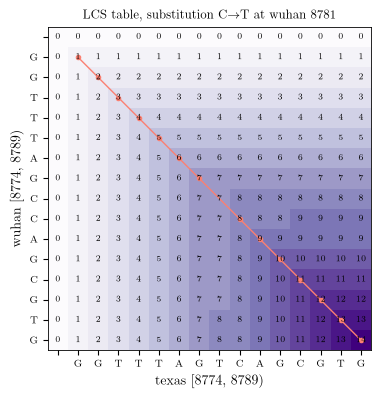

saved ../essay/figures/fig_hirschberg_splits.png


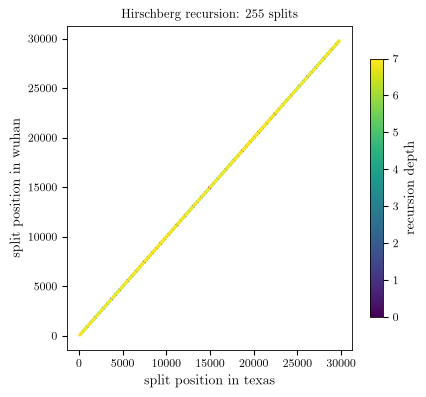

saved

 ../essay/figures/fig_mutation_map.png


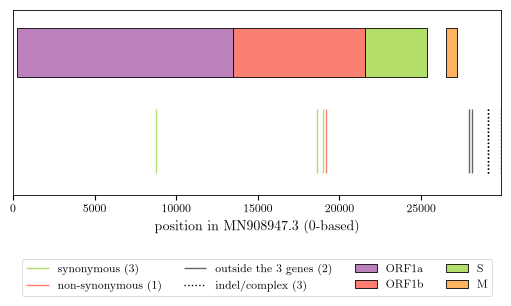

In [16]:
# figure: dp table with traceback on a small window around the first substitution
s0 = SUBS[0]
wx, wy = s0["x"] - 7, s0["y"] - 7
Xs, Ys = X[wx:wx + 15], Y[wy:wy + 15]
T, pairs_small = lcs_table(Xs, Ys)
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.imshow(np.array(T), cmap="Purples", origin="upper")
ax.plot([j + 1 for _, j in pairs_small], [i + 1 for i, _ in pairs_small], "o-", color=PALETTE[1], markersize=3, linewidth=1)
ax.set_xticks(range(len(Ys) + 1), [""] + list(Ys), fontsize=7)
ax.set_yticks(range(len(Xs) + 1), [""] + list(Xs), fontsize=7)
ax.set_xlabel(f"texas [{wy}, {wy + 15})")
ax.set_ylabel(f"wuhan [{wx}, {wx + 15})")
ax.set_title(f"LCS table, substitution {s0['from']}$\\to${s0['to']} at wuhan {s0['x']}", fontsize=9)
for i in range(len(Xs) + 1):
    for j in range(len(Ys) + 1):
        ax.text(j, i, T[i][j], ha="center", va="center", fontsize=5.5, color="black")
save_fig(fig, "fig_lcs_matrix")
plt.show()

# figure: hirschberg split points, one dot per recursive call
fig, ax = plt.subplots(figsize=(4.6, 4.2))
sp = np.array(SPLITS)
sc = ax.scatter(sp[:, 2], sp[:, 1], c=sp[:, 0], cmap="viridis", s=6, linewidths=0)
ax.set_xlabel("split position in texas")
ax.set_ylabel("split position in wuhan")
ax.set_title(f"Hirschberg recursion: {len(SPLITS)} splits", fontsize=9)
fig.colorbar(sc, ax=ax, label="recursion depth", shrink=0.8)
save_fig(fig, "fig_hirschberg_splits")
plt.show()

# figure: mutation map on the wuhan genome
def draw_mutation_map(coding, subs, events, name, outside_label):
    fig, ax = plt.subplots(figsize=(6.3, 2.4))
    many = len(coding) > 8
    for i, (region, a, b, _) in enumerate(coding):
        ax.barh(1.0, b - a, left=a, height=0.35, color=PALETTE[6] if many else PALETTE[i],
                label=(f"coding regions ({len(coding)})" if i == 0 else None) if many else region)
    colors = {"synonymous": PALETTE[2], "non-synonymous": PALETTE[1], "": "0.4"}
    for eff in ("synonymous", "non-synonymous", ""):
        xs = [s["x"] for s in subs if s["effect"] == eff]
        ax.vlines(xs, 0.15, 0.6, color=colors[eff], linewidth=1.0, label=f"{eff or outside_label} ({len(xs)})")
    xs = [e["x"] for e in events if e["kind"] != "substitution"]
    ax.vlines(xs, 0.15, 0.6, color="black", linewidth=1.0, linestyles="dotted", label=f"indel/complex ({len(xs)})")
    ax.set_xlim(0, len(X))
    ax.set_ylim(0, 1.3)
    ax.set_yticks([])
    ax.set_xlabel("position in MN908947.3 (0-based)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=4)
    save_fig(fig, name)
    plt.show()


draw_mutation_map(CODING, SUBS, EVENTS, "fig_mutation_map", "outside the 3 genes")

In [17]:
# benchmark: pure python rows vs numpy rows vs hirschberg on genome prefixes
BENCH["lcs"] = {"n_py": [500, 1000, 2000, 3000], "rows_py": [],
                "n": [1000, 2000, 5000, 10000, 20000, len(X)], "rows_np": [], "hirschberg": []}
for n in BENCH["lcs"]["n_py"]:
    BENCH["lcs"]["rows_py"].append(bench(lcs_rows_py, X[:n], Y[:n], repeats=1))
for n in BENCH["lcs"]["n"]:
    BENCH["lcs"]["rows_np"].append(bench(lcs_last_row, Xa[:n], Ya[:n], repeats=1))
    BENCH["lcs"]["hirschberg"].append(bench(hirschberg, Xa[:n], Ya[:n], repeats=1))
b = BENCH["lcs"]
print(f"{'n':>6s} {'rows_py':>10s}")
for n, t in zip(b["n_py"], b["rows_py"]):
    print(f"{n:6d} {t:9.3f}s")
print(f"{'n':>6s} {'rows_np':>10s} {'hirschberg':>11s}")
for n, t1, t2 in zip(b["n"], b["rows_np"], b["hirschberg"]):
    print(f"{n:6d} {t1:9.3f}s {t2:10.3f}s")
print("log-log slopes:", {k: round(loglog_slope(b["n_py" if k == "rows_py" else "n"], b[k]), 2) for k in ("rows_py", "rows_np", "hirschberg")})

     n    rows_py
   500     0.011s
  1000     0.045s
  2000     0.190s
  3000     0.432s
     n    rows_np  hirschberg
  1000     0.003s      0.009s
  2000     0.010s      0.028s
  5000     0.050s      0.132s
 10000     0.205s      0.475s
 20000     0.744s      1.803s
 29903     1.679s      3.793s
log-log slopes: {'rows_py': 2.07, 'rows_np': 1.86, 'hirschberg': 1.78}


## 4. greedy: maximum set of non-overlapping ORFs

**Problem.** An open reading frame (ORF) runs from a start codon `ATG` to the
first in-frame stop codon (`TAA`, `TAG`, `TGA`). Scanning the three forward
reading frames of the genome gives a set of candidate ORFs that overlap each
other. Which candidates form the largest set of non-overlapping ORFs? This is
the activity-selection problem: intervals with start and end, choose as many
pairwise-compatible ones as possible.

**Why greedy.** Sorting the candidates by end position and always taking the
earliest-ending compatible interval is optimal by the exchange argument: any
optimal solution can have its first interval swapped for the earliest-ending
one without losing compatibility, and induction does the rest. Cost:
$O(n)$ to scan the genome for candidates and $O(c \log c)$ to sort the $c$
candidates. An exhaustive search over subsets costs $O(2^c)$ and is run on a
small slice of the candidates to confirm that greedy reaches the optimum.

In [18]:
STOP = {"TAA", "TAG", "TGA"}


def find_orfs(seq, min_codons=100):
    # every in-frame atg up to the next in-frame stop, nested starts included
    # (start, end, frame, codons): end is past the stop codon, codons excludes it
    orfs = []
    for frame in range(3):
        opens = []
        for i in range(frame, len(seq) - 2, 3):
            cod = seq[i:i + 3]
            if cod == "ATG":
                opens.append(i)
            elif cod in STOP:
                for start in opens:
                    if (i - start) // 3 >= min_codons:
                        orfs.append((start, i + 3, frame, (i - start) // 3))
                opens = []
    return sorted(orfs)


def greedy_select(intervals):
    chosen, last_end = [], -1
    for iv in sorted(intervals, key=lambda t: t[1]):
        if iv[0] >= last_end:
            chosen.append(iv)
            last_end = iv[1]
    return chosen


def exhaustive_select(intervals):
    # every subset, keep the largest compatible one: o(2^c) subsets
    ivs = sorted(intervals)
    best = []
    for mask in range(1, 1 << len(ivs)):
        chosen = [ivs[b] for b in range(len(ivs)) if mask >> b & 1]
        if all(chosen[t + 1][0] >= chosen[t][1] for t in range(len(chosen) - 1)) and len(chosen) > len(best):
            best = chosen
    return best


ORFS = find_orfs(genome, min_codons=100)
SELECTED = greedy_select(ORFS)
print(f"candidate ORFs with at least 100 codons: {len(ORFS)}, greedy selects {len(SELECTED)}")

small = ORFS[::max(1, len(ORFS) // 14)][:14]
ex = exhaustive_select(small)
gr = greedy_select(small)
assert len(ex) == len(gr), (len(ex), len(gr))
print(f"{len(small)} candidates spread over the genome: exhaustive optimum {len(ex)}, greedy {len(gr)} (equal)")

KNOWN = {"ORF1ab": GENE_POS["orf1ab"], "S": GENE_POS["S"], "M": GENE_POS["M"]}


def overlaps_known(a, b):
    hits = []
    for name, (ka, kb) in KNOWN.items():
        ov = max(0, min(b, kb) - max(a, ka))
        if ov:
            hits.append(f"{name} ({ov / (kb - ka):.0%})")
    return ", ".join(hits) or "-"


print(f"\n{'start':>6s} {'end':>6s} {'frame':>5s} {'codons':>6s}  overlap with known genes (fraction of the gene covered)")
for a, b, f, c in SELECTED:
    print(f"{a:6d} {b:6d} {f:5d} {c:6d}  {overlaps_known(a, b)}")

# the objective matters: with a low length threshold, maximising the count
# favours many short orfs and the long genes lose out
for mc in (30, 50, 100):
    cand = find_orfs(genome, min_codons=mc)
    chosen = greedy_select(cand)
    exact = sum(1 for a, b, _, _ in chosen if (a, b) in KNOWN.values())
    print(f"min {mc:3d} codons: {len(cand):3d} candidates, greedy selects {len(chosen):2d}, "
          f"covers {sum(b - a for a, b, _, _ in chosen) / len(genome):.0%} of the genome, "
          f"{exact} of {len(KNOWN)} known genes recovered exactly")

candidate ORFs with at least 100 codons: 187, greedy selects 8
14 candidates spread over the genome: exhaustive optimum 3, greedy 3 (equal)

 start    end frame codons  overlap with known genes (fraction of the gene covered)
   265  13483     1   4405  ORF1ab (62%)
 13767  21555     0   2595  ORF1ab (37%)
 21562  25384     1   1273  S (100%)
 25392  26220     0    275  -
 26522  27191     2    222  M (100%)
 27393  27759     0    121  -
 27893  28259     2    121  -
 28273  29533     1    419  -
min  30 codons: 287 candidates, greedy selects 53, covers 30% of the genome, 0 of 3 known genes recovered exactly
min  50 codons: 217 candidates, greedy selects 23, covers 30% of the genome, 0 of 3 known genes recovered exactly
min 100 codons: 187 candidates, greedy selects  8, covers 95% of the genome, 2 of 3 known genes recovered exactly


saved ../essay/tables/tab_orfs.tex
saved ../essay/figures/fig_orf_map.png


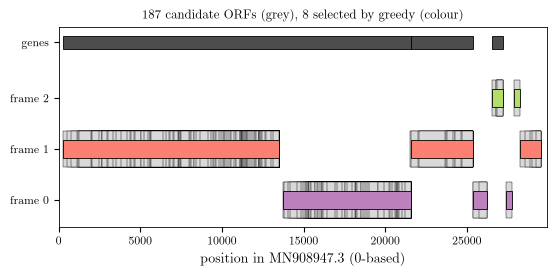

exhaustive vs greedy (s):
  c= 4    0.0000  0.000000
  c= 5    0.0000  0.000000
  c= 6    0.0000  0.000000
  c= 7    0.0000  0.000000
  c= 8    0.0001  0.000000
  c= 9    0.0002  0.000000
  c=10    0.0004  0.000000
  c=11    0.0009  0.000001
  c=12    0.0020  0.000001
  c=13    0.0042  0.000001
  c=14    0.0088  0.000001
  c=15    0.0185  0.000001
  c=16    0.0386  0.000001
find_orfs log-log slope: 1.01


In [19]:
rows = [f"{a} & {b} & {f} & {c} & {overlaps_known(a, b).replace('%', chr(92) + '%')} \\\\" for a, b, f, c in SELECTED]
save_table("tab_orfs", "\n".join([
    r"\begin{tabular}{rrrrl}", r"\hline",
    r"start & end & frame & codons & known gene overlap \\", r"\hline",
    *rows, r"\hline", r"\end{tabular}"]))

fig, ax = plt.subplots(figsize=(6.3, 2.6))
for a, b, f, c in ORFS:
    ax.barh(f, b - a, left=a, height=0.7, color="0.85", linewidth=0.3)
for a, b, f, c in SELECTED:
    ax.barh(f, b - a, left=a, height=0.35, color=PALETTE[f])
for i, (name, (ka, kb)) in enumerate(KNOWN.items()):
    ax.barh(3.1, kb - ka, left=ka, height=0.25, color="0.3", label="known genes" if i == 0 else None)
ax.set_yticks([0, 1, 2, 3.1], ["frame 0", "frame 1", "frame 2", "genes"])
ax.set_xlim(0, len(genome))
ax.set_xlabel("position in MN908947.3 (0-based)")
ax.set_title(f"{len(ORFS)} candidate ORFs (grey), {len(SELECTED)} selected by greedy (colour)", fontsize=9)
save_fig(fig, "fig_orf_map")
plt.show()

# benchmark: exhaustive grows as 2^c, greedy as c log c (candidates spread over the genome)
spread = ORFS[::max(1, len(ORFS) // 16)]
BENCH["orf"] = {"c": list(range(4, 17)), "exhaustive": [], "greedy": []}
for c in BENCH["orf"]["c"]:
    BENCH["orf"]["exhaustive"].append(bench(exhaustive_select, spread[:c], repeats=1))
    BENCH["orf"]["greedy"].append(bench(greedy_select, spread[:c], repeats=20))
BENCH["orf_scan"] = {"n": SIZES, "find_orfs": [bench(find_orfs, genome[:n]) for n in SIZES]}
print("exhaustive vs greedy (s):")
for c, te, tg in zip(BENCH["orf"]["c"], BENCH["orf"]["exhaustive"], BENCH["orf"]["greedy"]):
    print(f"  c={c:2d}  {te:8.4f}  {tg:8.6f}")
print("find_orfs log-log slope:", round(loglog_slope(SIZES, BENCH["orf_scan"]["find_orfs"]), 2))

## 5. backtracking: where is each protein encoded?

**Problem.** `seq-proteins.txt` lists the amino-acid sequences of the viral
proteins. Which stretch of the genome encodes each one? The genetic code is
degenerate (up to six codons per amino acid), so a protein of length $L$ has
up to $6^L$ possible DNA encodings and we cannot search for each one.

**Why backtracking.** Build the encoding one codon at a time. The state is the
set of genome positions that are still consistent with the codons chosen so
far; choosing the next codon filters that set. As soon as the set is empty
the partial encoding cannot occur anywhere in the genome and the whole
subtree is pruned. The search only needs the first $k$ amino acids: every
surviving position is then verified by translating the genome forward for
the full length of the protein. The baseline enumerates every encoding of the
same $k$-amino-acid prefix (the product of the codon degeneracies) and tests
each one.

In [20]:
def codon_index(seq):
    idx = defaultdict(list)
    for i in range(len(seq) - 2):
        idx[seq[i:i + 3]].append(i)
    return idx


CODON_IDX = codon_index(genome)


def locate_backtracking(protein, seq, idx, k=6):
    k = min(k, len(protein))
    stats = {"nodes": 0, "pruned": 0}
    hits = []

    def backtrack(depth, candidates):
        if depth == k:
            hits.extend(candidates)
            return
        off = 3 * depth
        for cod in CODONS_FOR[protein[depth]]:
            stats["nodes"] += 1
            if depth == 0:
                nxt = idx.get(cod, [])
            else:
                nxt = [p for p in candidates if seq[p + off:p + off + 3] == cod]
            if not nxt:
                stats["pruned"] += 1
                continue
            backtrack(depth + 1, nxt)

    backtrack(0, None)
    return sorted(hits), stats


def locate_bruteforce(protein, seq, idx, k=6):
    # enumerate every dna encoding of the first k amino acids and test each one
    k = min(k, len(protein))
    hits, tested = [], 0
    for codons in itertools.product(*(CODONS_FOR[aa] for aa in protein[:k])):
        tested += 1
        for p in idx.get(codons[0], []):
            if all(seq[p + 3 * t:p + 3 * t + 3] == codons[t] for t in range(1, k)):
                hits.append(p)
    return sorted(hits), tested


def matched_prefix(protein, seq, p):
    # number of leading amino acids reproduced by translating the genome from p
    for t in range(len(protein)):
        if CODON.get(seq[p + 3 * t:p + 3 * t + 3], "X") != protein[t]:
            return t
    return len(protein)


LOCATED = []
print(f"{'protein':12s} {'len':>5s} {'hits':>4s} {'start':>6s} {'end':>6s} {'frame':>5s} {'matched':>7s}  nodes/pruned")
for pid, prot in PROTEINS:
    hits, st = locate_backtracking(prot, genome, CODON_IDX, k=6)
    bf_hits, _ = locate_bruteforce(prot, genome, CODON_IDX, k=6)
    assert hits == bf_hits
    best = max(hits, key=lambda p: matched_prefix(prot, genome, p)) if hits else None
    matched = matched_prefix(prot, genome, best) if hits else 0
    full = matched == len(prot)
    LOCATED.append({"id": pid, "len": len(prot), "hits": len(hits), "start": best,
                    "end": best + 3 * len(prot) if hits else None, "frame": best % 3 if hits else None,
                    "matched": matched, "full": full, "nodes": st["nodes"], "pruned": st["pruned"]})
    print(f"{pid:12s} {len(prot):5d} {len(hits):4d} {best if hits else '-':>6} {best + 3 * len(prot) if hits else '-':>6} "
          f"{best % 3 if hits else '-':>5} {matched:4d}/{len(prot):<4d} {st['nodes']}/{st['pruned']}")

n_full = sum(r["full"] for r in LOCATED)
print(f"\n{n_full} of {len(LOCATED)} proteins validated over their full length")
for r in LOCATED:
    if not r["full"]:
        print(f"  {r['id']}: only the first {r['matched']} of {r['len']} amino acids match from position {r['start']}")

protein        len hits  start    end frame matched  nodes/pruned


QHD43415_1     180    1    265    805     1  180/180  41/32


QHD43415_2     638    1    805   2719     1  638/638  86/65


QHD43415_3    1945    1   2719   8554     1 1945/1945 76/56
QHD43415_4     500    1   8554  10054     1  500/500  41/27


QHD43415_5     306    1  10054  10972     1  306/306  97/66


QHD43415_6     290    1  10972  11842     1  290/290  140/103
QHD43415_7      83    1  11842  12091     1   83/83   56/31
QHD43415_8     198    1  12091  12685     1  198/198  86/64


QHD43415_9     113    1  12685  13024     1  113/113  42/30
QHD43415_10    139    1  13024  13441     1  139/139  68/45
QHD43415_11    932    1  13441  16237     1    9/932  90/58


QHD43415_12    601    1  16236  18039     0  601/601  102/76
QHD43415_13    527    1  18039  19620     0  527/527  42/26
QHD43415_14    346    1  19620  20658     0  346/346  142/87


QHD43415_15    298    1  20658  21552     0  298/298  143/93
QHD43416      1273    1  21562  25381     1 1273/1273 25/17
QHD43417       275    1  25392  26217     0  275/275  26/18
QHD43418        75    1  26244  26469     0   75/75   29/21
QHD43419       222    1  26522  27188     2  222/222  37/26
QHD43420        61    1  27201  27384     0   61/61   23/15
QHD43421       121    1  27393  27756     0  121/121  23/15


QHD43422       121    1  27893  28256     2  121/121  19/12
QHD43423       419    1  28273  29530     1  419/419  31/19
QHI42199        38    1  29557  29671     1   38/38   22/13

23 of 24 proteins validated over their full length
  QHD43415_11: only the first 9 of 932 amino acids match from position 13441


### using the located proteins to finish the mutation analysis

Section 3 could only classify substitutions inside the three gene files.
Every fully validated protein now gives a coding region with a known frame,
so the classification is repeated over all of them. For the protein that
spans the frameshift the ORF1b frame validated in section 3 is kept.

 wuhan  texas  change       region     codon    aa  effect
  8781   8781     C>T   QHD43415_4   AGC>AGT   S>S  synonymous
 18602  18602     T>C  QHD43415_13   CAT>CAC   H>H  synonymous
 18974  18974     T>A  QHD43415_13   GTT>GTA   V>V  synonymous
 19174  19174     A>C  QHD43415_13   GAT>GCT   D>A  non-synonymous
 27924  27924     C>T     QHD43422   ACA>ATA   T>I  non-synonymous
 28143  28143     T>C     QHD43422   TTA>TCA   L>S  non-synonymous
saved ../essay/tables/tab_genome_comparison.tex
saved ../essay/tables/tab_mutations.tex
saved ../essay/figures/fig_mutation_map.png


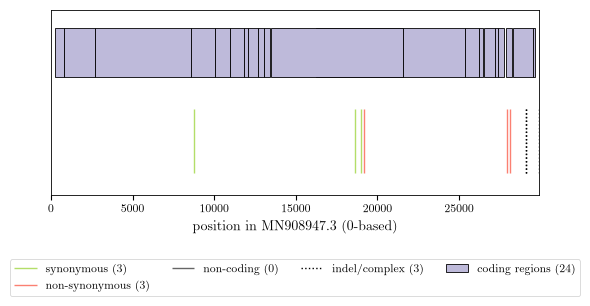

In [21]:
CODING_ALL = [(r["id"], r["start"], r["end"], r["start"]) for r in LOCATED if r["full"]] + CODING
SUBS_ALL = classify_substitutions(EVENTS, CODING_ALL, outside="non-coding")
print_substitutions(SUBS_ALL)
save_comparison_tables(SUBS_ALL)
# drawn regions: the validated proteins plus the orf1b frame that covers the frameshift protein
draw_mutation_map([c for c in CODING_ALL if c[0] not in ("S", "M", "ORF1a")], SUBS_ALL, EVENTS, "fig_mutation_map", "non-coding")

In [22]:
# table of located proteins
rows = [f"{r['id'].replace('_', chr(92) + '_')} & {r['len']} & {r['start']} & {r['end']} & {r['frame']} & {r['matched']}/{r['len']} & {r['nodes']} & {r['pruned']} \\\\" for r in LOCATED]
save_table("tab_proteins", "\n".join([
    r"\begin{tabular}{lrrrrrrr}", r"\hline",
    r"protein & length & start & end & frame & matched & nodes & pruned \\", r"\hline",
    *rows, r"\hline", r"\end{tabular}"]))

# benchmark on the protein whose 10-amino-acid prefix has the most encodings
def n_encodings(prot, k):
    return math.prod(len(CODONS_FOR[aa]) for aa in prot[:k])


hard_id, hard = max(PROTEINS, key=lambda r: n_encodings(r[1], 10))
print(f"hardest prefix: {hard_id} {hard[:10]} with {n_encodings(hard, 10)} encodings of its first 10 amino acids")
BENCH["backtracking"] = {"k": [], "bt_nodes": [], "bt_time": [], "bf_encodings": [], "bf_time": []}
for k in range(1, 11):
    hits, st = locate_backtracking(hard, genome, CODON_IDX, k=k)
    b = BENCH["backtracking"]
    b["k"].append(k)
    b["bt_nodes"].append(st["nodes"])
    b["bt_time"].append(bench(locate_backtracking, hard, genome, CODON_IDX, k, repeats=1))
    enc = n_encodings(hard, k)
    b["bf_encodings"].append(enc)
    if enc <= 300_000:
        bf_hits, tested = locate_bruteforce(hard, genome, CODON_IDX, k=k)
        assert bf_hits == hits and tested == enc
        b["bf_time"].append(bench(locate_bruteforce, hard, genome, CODON_IDX, k, repeats=1))
    else:
        b["bf_time"].append(None)
print(f"{'k':>2s} {'encodings':>10s} {'bf time':>9s} {'bt nodes':>8s} {'bt time':>9s}")
for i, k in enumerate(BENCH["backtracking"]["k"]):
    b = BENCH["backtracking"]
    bf = f"{b['bf_time'][i]:8.4f}s" if b["bf_time"][i] is not None else "  skipped"
    print(f"{k:2d} {b['bf_encodings'][i]:10d} {bf} {b['bt_nodes'][i]:8d} {b['bt_time'][i]:8.4f}s")

saved ../essay/tables/tab_proteins.tex
hardest prefix: QHD43415_8 AIASEFSSLP with 995328 encodings of its first 10 amino acids


 k  encodings   bf time bt nodes   bt time
 1          4   0.0001s        4   0.0000s
 2         12   0.0006s       16   0.0002s
 3         48   0.0024s       64   0.0002s
 4        288   0.0140s       82   0.0002s
 5        576   0.0280s       84   0.0002s
 6       1152   0.0566s       86   0.0002s
 7       6912   0.3419s       92   0.0002s
 8      41472   2.0244s       98   0.0002s
 9     248832  12.3275s      104   0.0002s
10     995328   skipped      108   0.0002s


## 6. branch and bound: the most frequent motif with mismatches

**Problem.** Find the $k$-mer that occurs most often in the genome when up to
$d$ mismatches are allowed. With $d = 0$ a single pass with a hash table
answers this in $O(nk)$, so exact counting is not where branch and bound
earns its place. With $d \ge 1$ the count of a candidate depends on all its
neighbours and there are $4^k$ candidates, each needing an $O(nk)$ scan.

**Why branch and bound.** Candidates are built one symbol at a time, so the
search space is a 4-ary tree of prefixes. A node carries the genome positions
whose window still agrees with the prefix within $d$ mismatches. The number
of those positions is an upper bound on the count of every completion of the
prefix: a window that matches a full $k$-mer within $d$ mismatches must also
match its prefix within $d$. Nodes are expanded best-first (a max-heap on the
bound, as in the knapsack example from class), an incumbent is obtained by a
greedy descent, and any node whose bound cannot beat the incumbent is pruned.
The exhaustive baseline walks the same tree with no bound.

In [23]:
def motif_children(seq, prefix, alive, d):
    depth = len(prefix)
    for c in "ACGT":
        nxt = []
        for p, mm in alive:
            if seq[p + depth] != c:
                mm += 1
                if mm > d:
                    continue
            nxt.append((p, mm))
        if nxt:
            yield prefix + c, nxt


def motif_exhaustive(seq, k, d):
    alive0 = [(p, 0) for p in range(len(seq) - k + 1)]
    best, best_motif, nodes = -1, None, 0
    stack = [("", alive0)]
    while stack:
        prefix, alive = stack.pop()
        nodes += 1
        if len(prefix) == k:
            if len(alive) > best:
                best, best_motif = len(alive), prefix
            continue
        stack.extend(motif_children(seq, prefix, alive, d))
    return best_motif, best, {"nodes": nodes, "pruned": 0}


def motif_bnb(seq, k, d):
    alive0 = [(p, 0) for p in range(len(seq) - k + 1)]
    # incumbent: greedy descent, always the child with the largest bound
    prefix, alive = "", alive0
    for _ in range(k):
        prefix, alive = max(motif_children(seq, prefix, alive, d), key=lambda t: len(t[1]))
    best, best_motif = len(alive), prefix
    nodes = pruned = 0
    heap = [(-len(alive0), "", alive0)]
    while heap:
        neg_bound, prefix, alive = heapq.heappop(heap)
        if -neg_bound <= best:
            pruned += 1
            continue
        nodes += 1
        if len(prefix) == k:
            best, best_motif = len(alive), prefix
            continue
        for child, nxt in motif_children(seq, prefix, alive, d):
            if len(nxt) <= best:
                pruned += 1
            else:
                heapq.heappush(heap, (-len(nxt), child, nxt))
    return best_motif, best, {"nodes": nodes, "pruned": pruned}


# check 1: with d = 0 the answer is the plain hash count
motif0, count0, _ = motif_bnb(genome, 8, 0)
counts8 = kmer_counts(genome, 8)
assert count0 == max(counts8.values()), (count0, max(counts8.values()))
print(f"d=0, k=8: {motif0} x{count0}, equals the hash count maximum")

# check 2: with d = 1 exhaustive and branch and bound agree on the optimum
BENCH["bnb"] = {"k": [], "ex_nodes": [], "ex_time": [], "bnb_nodes": [], "bnb_time": [], "motif": [], "count": []}
for k in (5, 6, 7, 8, 10, 12):
    b = BENCH["bnb"]
    t0 = time.perf_counter()
    m_b, c_b, s_b = motif_bnb(genome, k, 1)
    t_b = time.perf_counter() - t0
    if k <= 8:
        t0 = time.perf_counter()
        m_e, c_e, s_e = motif_exhaustive(genome, k, 1)
        t_e = time.perf_counter() - t0
        assert c_e == c_b, (k, c_e, c_b)
    else:
        s_e, t_e = {"nodes": None}, None
    b["k"].append(k)
    b["bnb_nodes"].append(s_b["nodes"])
    b["bnb_time"].append(t_b)
    b["ex_nodes"].append(s_e["nodes"])
    b["ex_time"].append(t_e)
    b["motif"].append(m_b)
    b["count"].append(c_b)
    ex = f"{s_e['nodes']:7d} nodes {t_e:6.2f}s" if t_e is not None else "        skipped     "
    print(f"k={k:2d} d=1: {m_b:12s} x{c_b:4d} | exhaustive {ex} | b&b {s_b['nodes']:6d} nodes, {s_b['pruned']:6d} pruned, {t_b:6.2f}s")

rows = [f"{k} & 1 & {m} & {c} & {ex if ex is not None else '--'} & {bn} \\\\" for k, m, c, ex, bn in zip(BENCH['bnb']['k'], BENCH['bnb']['motif'], BENCH['bnb']['count'], BENCH['bnb']['ex_nodes'], BENCH['bnb']['bnb_nodes'])]
save_table("tab_motif", "\n".join([
    r"\begin{tabular}{rrlrrr}", r"\hline",
    r"$k$ & $d$ & best motif & count & exhaustive nodes & B\&B nodes \\", r"\hline",
    *rows, r"\hline", r"\end{tabular}"]))

d=0, k=8: AAAAAAAA x26, equals the hash count maximum


k= 5 d=1: TTTTT        x1241 | exhaustive    1365 nodes   0.19s | b&b    263 nodes,    786 pruned,   0.19s


k= 6 d=1: TTTTTT       x 418 | exhaustive    5461 nodes   0.26s | b&b    907 nodes,   2718 pruned,   0.27s


k= 7 d=1: TGTTGTT      x 193 | exhaustive   21836 nodes   0.36s | b&b   2252 nodes,   6753 pruned,   0.34s


k= 8 d=1: TGTTGTTA     x  75 | exhaustive   85695 nodes   0.49s | b&b   6383 nodes,  19146 pruned,   0.53s


k=10 d=1: AAAAGAAAAA   x  33 | exhaustive         skipped      | b&b  15575 nodes,  46715 pruned,   0.68s


k=12 d=1: AAAAAAAAAAAA x  24 | exhaustive         skipped      | b&b  22445 nodes,  67242 pruned,   0.75s
saved ../essay/tables/tab_motif.tex


## 7. extra: palindromic regions with Manacher's algorithm

**Problem.** Within a gene, palindromic stretches are regions prone to
mutation. Which is the longest palindrome (read identically left to right
and right to left) in each gene?

**Baseline.** Expand around every one of the $2n - 1$ centres: $O(n^2)$ in the
worst case (a run of a single symbol), close to linear on real DNA because
most expansions stop after a few symbols.

**Manacher.** Interleave a separator so that every palindrome has odd length,
then reuse the radius of the mirror centre inside the rightmost known
palindrome. Each symbol extends the right boundary at most once, so the whole
array of radii costs $O(n)$.

In [24]:
def longest_palindrome_center(s):
    best_len, best_start = 0, 0
    for c in range(len(s)):
        for lo, hi in ((c, c), (c, c + 1)):
            while lo >= 0 and hi < len(s) and s[lo] == s[hi]:
                lo, hi = lo - 1, hi + 1
            if hi - lo - 1 > best_len:
                best_len, best_start = hi - lo - 1, lo + 1
    return best_start, best_len


def manacher(s):
    t = "^#" + "#".join(s) + "#$"
    n = len(t)
    p = [0] * n
    c = r = 0
    for i in range(1, n - 1):
        if i < r:
            p[i] = min(r - i, p[2 * c - i])
        while t[i + p[i] + 1] == t[i - p[i] - 1]:
            p[i] += 1
        if i + p[i] > r:
            c, r = i, i + p[i]
    best_len, best_center = 0, 0
    for i in range(1, n - 1):
        if p[i] > best_len:
            best_len, best_center = p[i], i
    return (best_center - best_len) // 2, best_len


PALS = []
print(f"{'gene':7s} {'length':>6s} {'palindrome':>28s} {'start':>6s} {'end':>6s} {'len':>4s}")
for g in ("M", "S", "orf1ab"):
    seq_g = SEQ[g]
    s1, l1 = longest_palindrome_center(seq_g)
    s2, l2 = manacher(seq_g)
    assert l1 == l2 and seq_g[s2:s2 + l2] == seq_g[s2:s2 + l2][::-1]
    PALS.append((g, len(seq_g), seq_g[s2:s2 + l2], s2, s2 + l2, l2))
    print(f"{g:7s} {len(seq_g):6d} {seq_g[s2:s2 + l2]:>28s} {s2:6d} {s2 + l2:6d} {l2:4d}")

rows = [f"{g} & {n} & \\texttt{{{pal}}} & {a} & {b} & {l} \\\\" for g, n, pal, a, b, l in PALS]
save_table("tab_palindromes", "\n".join([
    r"\begin{tabular}{lrlrrr}", r"\hline",
    r"gene & length & longest palindrome & start & end & length \\", r"\hline",
    *rows, r"\hline", r"\end{tabular}"]))

# benchmark: real dna, and the adversarial single-symbol run
BENCH["pal_real"] = {"n": SIZES, "center": [], "manacher": []}
for n in SIZES:
    BENCH["pal_real"]["center"].append(bench(longest_palindrome_center, genome[:n]))
    BENCH["pal_real"]["manacher"].append(bench(manacher, genome[:n]))
adv_sizes = [500, 1000, 2000, 4000]
BENCH["pal_adv"] = {"n": adv_sizes, "center": [], "manacher": []}
for n in adv_sizes:
    BENCH["pal_adv"]["center"].append(bench(longest_palindrome_center, "A" * n, repeats=1))
    BENCH["pal_adv"]["manacher"].append(bench(manacher, "A" * n))
for key in ("pal_real", "pal_adv"):
    b = BENCH[key]
    print(key, "slopes:", {k: round(loglog_slope(b["n"], b[k]), 2) for k in ("center", "manacher")})

gene    length                   palindrome  start    end  len
M          669                  CTAAAGAAATC    493    504   11
S         3822              GAATTTGTGTTTAAG    570    585   15
orf1ab   21290         CTCAATGACTTCAGTAACTC   9711   9731   20
saved ../essay/tables/tab_palindromes.tex


pal_real slopes: {'center': 1.04, 'manacher': 1.02}
pal_adv slopes: {'center': 2.02, 'manacher': 1.04}


## 8. performance

Every technique was timed against its baseline on growing inputs. The
log-log slope of a series estimates the exponent $b$ in $t \propto n^b$, so a
linear algorithm should show $b \approx 1$ and a quadratic one $b \approx 2$.
Dashed lines show the theoretical growth anchored at the largest measured
point. For the search-tree techniques (greedy vs exhaustive, backtracking vs
brute force, branch and bound vs exhaustive) the natural axis is the size of
the search space, so those are plotted against $c$ or $k$.

saved ../essay/figures/fig_time_scaling.png


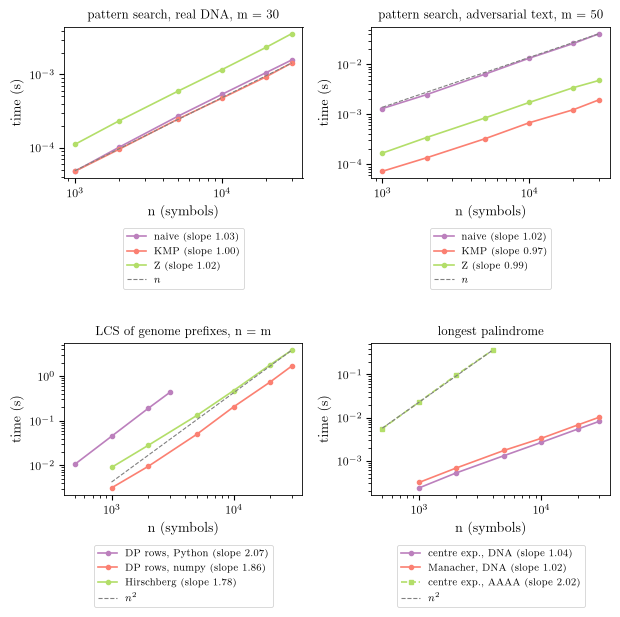

In [25]:
def ref_line(ax, ns, ts, exponent, label):
    ns = np.array(ns, dtype=float)
    ts = np.array(ts, dtype=float)
    scale = ts[-1] / ns[-1] ** exponent
    ax.plot(ns, scale * ns ** exponent, "--", color="0.5", linewidth=0.8, label=label)


fig, axes = plt.subplots(2, 2, figsize=(6.3, 6.5))
ax = axes[0, 0]
b = BENCH["search_real"]
for key, lab in (("naive", "naive"), ("kmp", "KMP"), ("z", "Z")):
    ax.loglog(b["n"], b[key], "o-", markersize=3, label=f"{lab} (slope {loglog_slope(b['n'], b[key]):.2f})")
ref_line(ax, b["n"], b["kmp"], 1, r"$n$")
ax.set_title("pattern search, real DNA, m = 30", fontsize=9)

ax = axes[0, 1]
b = BENCH["search_adv"]
for key, lab in (("naive", "naive"), ("kmp", "KMP"), ("z", "Z")):
    ax.loglog(b["n"], b[key], "o-", markersize=3, label=f"{lab} (slope {loglog_slope(b['n'], b[key]):.2f})")
ref_line(ax, b["n"], b["naive"], 1, r"$n$")
ax.set_title("pattern search, adversarial text, m = 50", fontsize=9)

ax = axes[1, 0]
b = BENCH["lcs"]
ax.loglog(b["n_py"], b["rows_py"], "o-", markersize=3, label=f"DP rows, Python (slope {loglog_slope(b['n_py'], b['rows_py']):.2f})")
ax.loglog(b["n"], b["rows_np"], "o-", markersize=3, label=f"DP rows, numpy (slope {loglog_slope(b['n'], b['rows_np']):.2f})")
ax.loglog(b["n"], b["hirschberg"], "o-", markersize=3, label=f"Hirschberg (slope {loglog_slope(b['n'], b['hirschberg']):.2f})")
ref_line(ax, b["n"], b["hirschberg"], 2, r"$n^2$")
ax.set_title("LCS of genome prefixes, n = m", fontsize=9)

ax = axes[1, 1]
b = BENCH["pal_real"]
ax.loglog(b["n"], b["center"], "o-", markersize=3, label=f"centre exp., DNA (slope {loglog_slope(b['n'], b['center']):.2f})")
ax.loglog(b["n"], b["manacher"], "o-", markersize=3, label=f"Manacher, DNA (slope {loglog_slope(b['n'], b['manacher']):.2f})")
b = BENCH["pal_adv"]
ax.loglog(b["n"], b["center"], "s--", markersize=3, label=f"centre exp., AAAA (slope {loglog_slope(b['n'], b['center']):.2f})")
ref_line(ax, b["n"], b["center"], 2, r"$n^2$")
ax.set_title("longest palindrome", fontsize=9)

for ax in axes.flat:
    ax.set_xlabel("n (symbols)")
    ax.set_ylabel("time (s)")
for ax in axes.flat:
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=1, fontsize=7, framealpha=0.85)
fig.tight_layout()
save_fig(fig, "fig_time_scaling")
plt.show()

saved ../essay/figures/fig_search_space.png


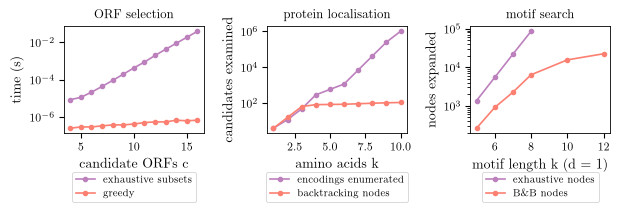

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(6.3, 2.5))
ax = axes[0]
b = BENCH["orf"]
ax.semilogy(b["c"], b["exhaustive"], "o-", markersize=3, label="exhaustive subsets")
ax.semilogy(b["c"], b["greedy"], "o-", markersize=3, label="greedy")
ax.set_xlabel("candidate ORFs c")
ax.set_ylabel("time (s)")
ax.set_title("ORF selection", fontsize=9)

ax = axes[1]
b = BENCH["backtracking"]
ax.semilogy(b["k"], b["bf_encodings"], "o-", markersize=3, label="encodings enumerated")
ax.semilogy(b["k"], b["bt_nodes"], "o-", markersize=3, label="backtracking nodes")
ax.set_xlabel("amino acids k")
ax.set_ylabel("candidates examined")
ax.set_title("protein localisation", fontsize=9)

ax = axes[2]
b = BENCH["bnb"]
ks = [k for k, v in zip(b["k"], b["ex_nodes"]) if v is not None]
ax.semilogy(ks, [v for v in b["ex_nodes"] if v is not None], "o-", markersize=3, label="exhaustive nodes")
ax.semilogy(b["k"], b["bnb_nodes"], "o-", markersize=3, label=f"B{AMP}B nodes")
ax.set_xlabel("motif length k (d = 1)")
ax.set_ylabel("nodes expanded")
ax.set_title("motif search", fontsize=9)
for ax in axes:
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=1, fontsize=7, framealpha=0.85)
fig.tight_layout()
save_fig(fig, "fig_search_space")
plt.show()

In [27]:
b_s, b_a, b_l, b_p, b_pa = BENCH["search_real"], BENCH["search_adv"], BENCH["lcs"], BENCH["pal_real"], BENCH["pal_adv"]
b_bt, b_bb, b_o = BENCH["backtracking"], BENCH["bnb"], BENCH["orf"]
sl = lambda ns, ts: f"{loglog_slope(ns, ts):.2f}"
ms = lambda t: f"{t * 1e3:.1f} ms" if t < 1 else f"{t:.2f} s"
rows = [
    ("naive search", "brute force", "$O(nm)$", sl(b_s["n"], b_s["naive"]), sl(b_a["n"], b_a["naive"]), f"{ms(b_s['naive'][-1])} / {ms(b_a['naive'][-1])}, $n = {b_s['n'][-1]}$"),
    ("KMP", "string", "$O(n + m)$", sl(b_s["n"], b_s["kmp"]), sl(b_a["n"], b_a["kmp"]), f"{ms(b_s['kmp'][-1])} / {ms(b_a['kmp'][-1])}, $n = {b_s['n'][-1]}$"),
    ("Z-function", "string", "$O(n + m)$", sl(b_s["n"], b_s["z"]), sl(b_a["n"], b_a["z"]), f"{ms(b_s['z'][-1])} / {ms(b_a['z'][-1])}, $n = {b_s['n'][-1]}$"),
    ("LCS rows, Python", "DP", "$O(nm)$ time, $O(m)$ space", sl(b_l["n_py"], b_l["rows_py"]), "--", f"{ms(b_l['rows_py'][-1])}, $n = {b_l['n_py'][-1]}$"),
    ("LCS rows, numpy", "DP", "$O(nm)$ time, $O(m)$ space", sl(b_l["n"], b_l["rows_np"]), "--", f"{ms(b_l['rows_np'][-1])}, $n = {b_l['n'][-1]}$"),
    ("Hirschberg", "D\\&C + DP", "$O(nm)$ time, $O(n + m)$ space", sl(b_l["n"], b_l["hirschberg"]), "--", f"{ms(b_l['hirschberg'][-1])}, $n = {b_l['n'][-1]}$"),
    ("ORF selection", "greedy", "$O(n + c \\log c)$ vs $O(2^c)$", sl(BENCH["orf_scan"]["n"], BENCH["orf_scan"]["find_orfs"]) + " (scan)", "--", f"exhaustive {ms(b_o['exhaustive'][-1])}, $c = {b_o['c'][-1]}$"),
    ("protein localisation", "backtracking", "$O(6^k)$ worst, pruned", "--", "--", f"{b_bt['bt_nodes'][-1]} vs {b_bt['bf_encodings'][-1]} nodes, $k = {b_bt['k'][-1]}$"),
    ("motif search", "branch and bound", "$O(4^k n)$ worst, pruned", "--", "--", f"{b_bb['bnb_nodes'][3]} vs {b_bb['ex_nodes'][3]} nodes, $k = {b_bb['k'][3]}$"),
    ("centre expansion", "brute force", "$O(n^2)$", sl(b_p["n"], b_p["center"]), sl(b_pa["n"], b_pa["center"]), f"{ms(b_p['center'][-1])} / {ms(b_pa['center'][-1])}"),
    ("Manacher", "string", "$O(n)$", sl(b_p["n"], b_p["manacher"]), sl(b_pa["n"], b_pa["manacher"]), f"{ms(b_p['manacher'][-1])} / {ms(b_pa['manacher'][-1])}"),
]
tex_rows = [" & ".join(r) + " \\\\" for r in rows]
save_table("tab_complexity", "\n".join([
    r"\begin{tabular}{>{\raggedright\arraybackslash}p{2.6cm}>{\raggedright\arraybackslash}p{2.5cm}>{\raggedright\arraybackslash}p{3.9cm}>{\raggedright\arraybackslash}p{1.3cm}>{\raggedright\arraybackslash}p{1.1cm}>{\raggedright\arraybackslash}p{3.7cm}}", r"\hline",
    r"algorithm & technique & complexity & slope real & slope adv. & largest run (real / adv.) \\", r"\hline",
    *tex_rows, r"\hline", r"\end{tabular}"]))
print(f"full table would need {len(X) * len(Y) * 4 / 1e9:.2f} GB; two rows need {2 * (len(Y) + 1) * 4 / 1e3:.0f} KB")

saved ../essay/tables/tab_complexity.tex
full table would need 3.57 GB; two rows need 239 KB


## 9. summary

| technique | question answered on the data | key result |
|---|---|---|
| naive, KMP, Z | where are the genes in the genome | all three agree with the header coordinates; naive is quadratic only on adversarial text |
| DP (LCS) + D&C (Hirschberg) | Wuhan 2019 vs Texas 2020 | similarity 0.999, a handful of substitutions with their amino-acid effect, in 4 s and a few rows of memory instead of 3.6 GB |
| greedy | largest set of non-overlapping ORFs | S and M recovered exactly; the objective (count, not coverage) is what makes the threshold matter |
| backtracking | where each protein is encoded | 23 of 24 proteins located over their full length; the exception breaks at the ribosomal frameshift |
| branch and bound | most frequent motif with one mismatch | same optimum as exhaustive search with about 7% of the nodes; the bound is loose at shallow depth so wall time barely moves |
| Manacher | longest palindrome per gene | same answer as centre expansion, linear instead of quadratic on adversarial input |

In [28]:
print("summary of numbers used in the report")
print(f"  lcs length {LCS_LEN}, similarity {SIMILARITY:.5f}, substitutions {len(SUBS_ALL)}, "
      f"synonymous {sum(s['effect'] == 'synonymous' for s in SUBS_ALL)}, non-synonymous {sum(s['effect'] == 'non-synonymous' for s in SUBS_ALL)}")
print(f"  hirschberg {t_hirschberg:.2f} s, numpy rows {t_rows:.2f} s, splits {len(SPLITS)}")
print(f"  orfs: {len(ORFS)} candidates, {len(SELECTED)} selected")
print(f"  proteins located in full: {n_full}/{len(LOCATED)}")
print(f"  motif k=8 d=1: {BENCH['bnb']['motif'][3]} x{BENCH['bnb']['count'][3]}, b&b {BENCH['bnb']['bnb_nodes'][3]} vs exhaustive {BENCH['bnb']['ex_nodes'][3]} nodes")
print(f"  palindromes: " + ", ".join(f"{g} {l} nt" for g, _, _, _, _, l in PALS))

summary of numbers used in the report
  lcs length 29875, similarity 0.99906, substitutions 6, synonymous 3, non-synonymous 3
  hirschberg 3.69 s, numpy rows 1.64 s, splits 255
  orfs: 187 candidates, 8 selected
  proteins located in full: 23/24
  motif k=8 d=1: TGTTGTTA x75, b&b 6383 vs exhaustive 85695 nodes
  palindromes: M 11 nt, S 15 nt, orf1ab 20 nt
